In [2]:
from pathlib import Path
import numpy as np
import rasterio
import matplotlib.pyplot as plt

safe_dir = Path("./S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE")
if not safe_dir.exists():
    raise FileNotFoundError(f"Directory {safe_dir} does not exist.")

In [3]:
b04 = next(safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B04_10m.jp2"))
b08 = next(safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B08_10m.jp2"))

with rasterio.open(b04) as src:
    red = src.read(1).astype(np.float32)
    profile = src.profile 
    red_nodata = src.nodata

with rasterio.open(b08) as src:
    nir = src.read(1).astype(np.float32)
    nir_nodata = src.nodata

print("RED shape:", red.shape, "dtype:", red.dtype, "nodata:", red_nodata, "min/max:", float(np.min(red)), float(np.max(red)))
print("NIR shape:", nir.shape, "dtype:", nir.dtype, "nodata:", nir_nodata, "min/max:", float(np.min(nir)), float(np.max(nir)))


RED shape: (10980, 10980) dtype: float32 nodata: None min/max: 0.0 17840.0
NIR shape: (10980, 10980) dtype: float32 nodata: None min/max: 0.0 16961.0


# Roi definition as the highest NDVI region

In [4]:
import numpy as np
import rasterio
from rasterio.windows import from_bounds
import matplotlib.pyplot as plt

#Defining region of interest (ROI)
roi_km = 20 #it is the size of the area we want to analyze, in kilometers, we will convert it to meters since the resolution is in meters
roi_m = roi_km * 1000 #converting km to meters
target_resolution_m = 200 #target resolution in meters (e.g., 200m) for efficient processing, we will downsample the original 10m resolution to this target resolution
real_resolution_m = 10

#Calculating the number of pixels needed to cover the ROI at the target resolution
roi_num_pixels = int(roi_m / target_resolution_m) 

with rasterio.open(b04) as src_red: 
    #original dimensions and resolution
    H, W = src_red.height, src_red.width

    #downsampled dimensions
    H_ds = int(H * real_resolution_m / target_resolution_m)
    W_ds = int(W * real_resolution_m / target_resolution_m)

    red_ds = src_red.read(1, out_shape=(H_ds, W_ds), resampling=rasterio.enums.Resampling.average).astype(np.float32)
    # trasnform is needed to georeference the pixels in the image, since we are downsampling, 
    # we need to adjust the transform to reflect the new pixel size
    transform_ds = src_red.transform * src_red.transform.scale((W / W_ds), (H / H_ds))

with rasterio.open(b08) as src_nir:
    nir_ds = src_nir.read(1, out_shape=(H_ds, W_ds), resampling=rasterio.enums.Resampling.average).astype(np.float32)
    # Here transform is no needed since we will use the same transform as the red band, 
    # but if we were to calculate it separately, it would be the same as for the red band
    # transform_ds_nir = src_nir.transform * src_nir.transform.scale((W / W_ds), (H / H_ds))

#ndvi is calculated as (NIR - RED) / (NIR + RED), we add a small value to the denominator to avoid division by zero, it is a common practice in remote sensing to avoid issues with pixels that have no data or very low values
ndvi_ds = (nir_ds - red_ds) / (nir_ds + red_ds + 1e-6) # adding a small value to avoid division by zero

# maschera semplice: escludo valori non plausibili o pixel “vuoti”
mask = np.isfinite(ndvi_ds) & (ndvi_ds > -0.2) & (ndvi_ds < 1.0) & (red_ds > 0) & (nir_ds > 0)
ndvi_ds_masked = np.where(mask, ndvi_ds, np.nan)

print("Downsampled NDVI shape:", ndvi_ds.shape, ", as 10980/20 = ", 10980/20, "\nROI window (px):", roi_num_pixels, "\nNDVI min/max (masked):", float(np.nanmin(ndvi_ds_masked)), float(np.nanmax(ndvi_ds_masked)))


Downsampled NDVI shape: (549, 549) , as 10980/20 =  549.0 
ROI window (px): 100 
NDVI min/max (masked): -0.19953051209449768 0.8134840726852417


Best window top-left corner: (160, 91), mean NDVI: 0.5774


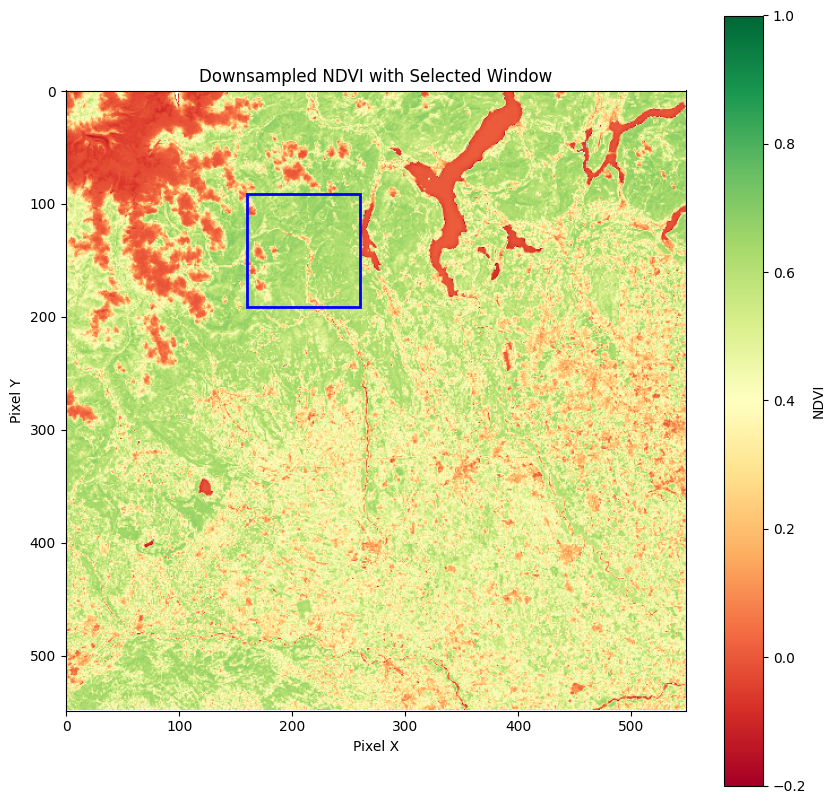

In [5]:
def window_with_highest_ndvi(ndvi_array, window_size):
    valid = np.isfinite(ndvi_array).astype(np.float32)
    a = np.nan_to_num(ndvi_array, nan=0.0).astype(np.float32)

    S = np.cumsum(np.cumsum(a, axis=0), axis=1)
    C = np.cumsum(np.cumsum(valid, axis=0), axis=1)

    def box_sum(M):
        # somma su tutte le finestre window_size×window_size
        return (M[window_size:, window_size:]
                - M[:-window_size, window_size:]
                - M[window_size:, :-window_size]
                + M[:-window_size, :-window_size])

    sum_ndvi = box_sum(S)
    count_valid = box_sum(C)

    mean_ndvi = np.where(count_valid > 0, sum_ndvi / count_valid, -np.inf)

    y, x = np.unravel_index(np.argmax(mean_ndvi), mean_ndvi.shape)
    return x, y, float(mean_ndvi[y, x])

x0_200m, y0_200m, max_ndvi_200m = window_with_highest_ndvi(ndvi_ds_masked, roi_num_pixels)
print(f"Best window top-left corner: ({x0_200m}, {y0_200m}), mean NDVI: {max_ndvi_200m:.4f}")


# Visualize the NDVI and the selected window
plt.figure(figsize=(10, 10))
plt.imshow(ndvi_ds_masked, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
rect = plt.Rectangle((x0_200m, y0_200m), roi_num_pixels, roi_num_pixels, edgecolor='blue', facecolor='none', linewidth=2)
plt.gca().add_patch(rect)
plt.title('Downsampled NDVI with Selected Window')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

In [6]:
# print roi size
print(f"ROI size in pixels: {roi_num_pixels}x{roi_num_pixels}, which corresponds to {roi_km}km x {roi_km}km at {target_resolution_m}m resolution.")

ROI size in pixels: 100x100, which corresponds to 20km x 20km at 200m resolution.


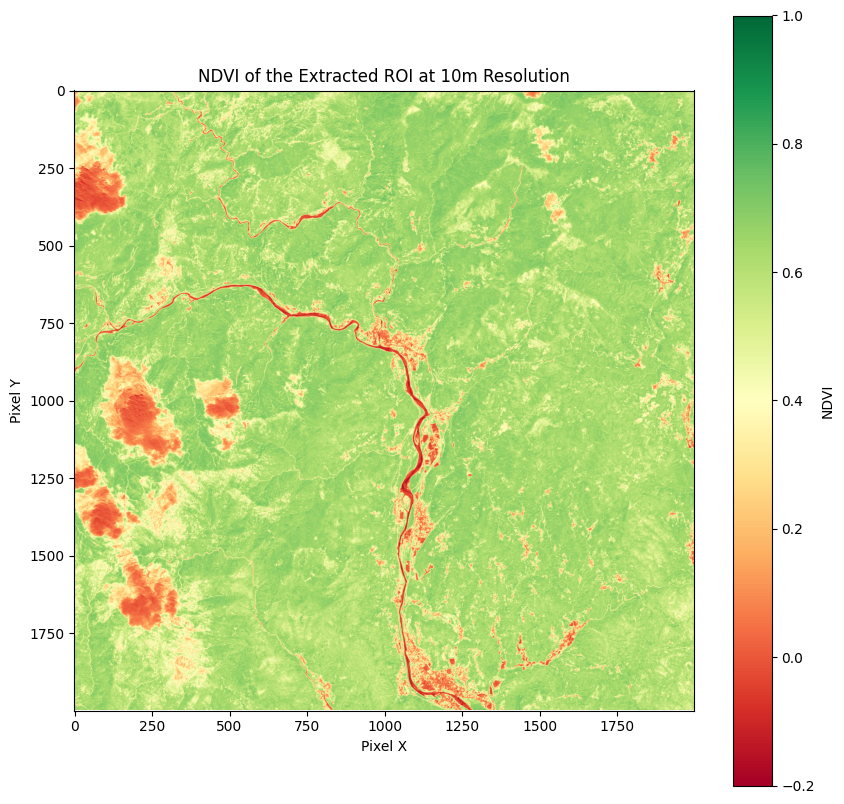

In [7]:
from rasterio.windows import Window #for extracting the roi from the original 10m resolution image

# Roi extraction
scale_factor_10m = target_resolution_m // real_resolution_m # -> 200 / 10 = 20
x0_10m = int(x0_200m * scale_factor_10m)
y0_10m = int(y0_200m * scale_factor_10m)

scale_factor_20m = target_resolution_m // 20 # -> 200 / 20 = 10
x0_20m = int(x0_200m * scale_factor_20m)
y0_20m = int(y0_200m * scale_factor_20m)

with rasterio.open(b04) as src_red: 
    # Window(col_off, row_off, width, height) 
    window_10m = Window(x0_10m, y0_10m, roi_num_pixels * scale_factor_10m, roi_num_pixels * scale_factor_10m)
    window_20m = Window(x0_20m, y0_20m, roi_num_pixels * scale_factor_20m, roi_num_pixels * scale_factor_20m)
    red_roi_10m = src_red.read(1, window=window_10m).astype(np.float32)

with rasterio.open(b08) as src_nir:
    nir_roi_10m = src_nir.read(1, window=window_10m).astype(np.float32)

ndvi_roi_10m = (nir_roi_10m - red_roi_10m) / (nir_roi_10m + red_roi_10m + 1e-6)

plt.figure(figsize=(10, 10))
plt.imshow(ndvi_roi_10m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
plt.title('NDVI of the Extracted ROI at 10m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()


Sentinel-2 MSI features 13 spectral bands with spatial resolutions of 10m, 20m, and 60m.  
The highest 10m resolution applies to visible and near-infrared (VNIR) bands (B2, B3, B4, B8),  
while red-edge/SWIR bands (B5, B6, B7, B8A, B11, B12) are 20m, and atmospheric bands (B1, B9, B10) are 60m

In [8]:
def find_10m_bands(path_to_safe):
    safe_dir = Path(path_to_safe)
    if not safe_dir.exists():
        raise FileNotFoundError(f"Directory {safe_dir} does not exist.")
    
    bands_10m = sorted(
        safe_dir.glob("GRANULE/*/IMG_DATA/R10m/*B*_10m.jp2")
    )
    return bands_10m

def find_20m_bands(path_to_safe):
    safe_dir = Path(path_to_safe)
    if not safe_dir.exists():
        raise FileNotFoundError(f"Directory {safe_dir} does not exist.")
    
    bands_20m = sorted(
        safe_dir.glob("GRANULE/*/IMG_DATA/R20m/*B*_20m.jp2")
    )

    return bands_20m

bands_10m = find_10m_bands(safe_dir)
bands_20m = find_20m_bands(safe_dir)

print("Bands at 10m resolution found:")
for band in bands_10m:
    print(band)

print("\nBands at 20m resolution found:")
for band in bands_20m:
    print(band)

Bands at 10m resolution found:
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B02_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B03_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B04_10m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R10m/T32TMR_20210625T102021_B08_10m.jp2

Bands at 20m resolution found:
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R20m/T32TMR_20210625T102021_B01_20m.jp2
S2A_MSIL2A_20210625T102021_N0500_R065_T32TMR_20230319T054911.SAFE/GRANULE/L2A_T32TMR_A031379_20210625T102545/IMG_DATA/R20m/T32TMR_20210625T102021_B


Extracted bands at 20m resolution stored in dictionary with keys:
B01
B02
B03
B04
B05
B06
B07
B11
B12
B8A

Shapes of extracted 10m bands:
Band 1: (2000, 2000)
Band 2: (2000, 2000)
Band 3: (2000, 2000)
Band 4: (2000, 2000)

Shapes of extracted 20m bands:
Band 1: (1000, 1000)
Band 2: (1000, 1000)
Band 3: (1000, 1000)
Band 4: (1000, 1000)
Band 5: (1000, 1000)
Band 6: (1000, 1000)
Band 7: (1000, 1000)
Band 8: (1000, 1000)
Band 9: (1000, 1000)
Band 10: (1000, 1000)


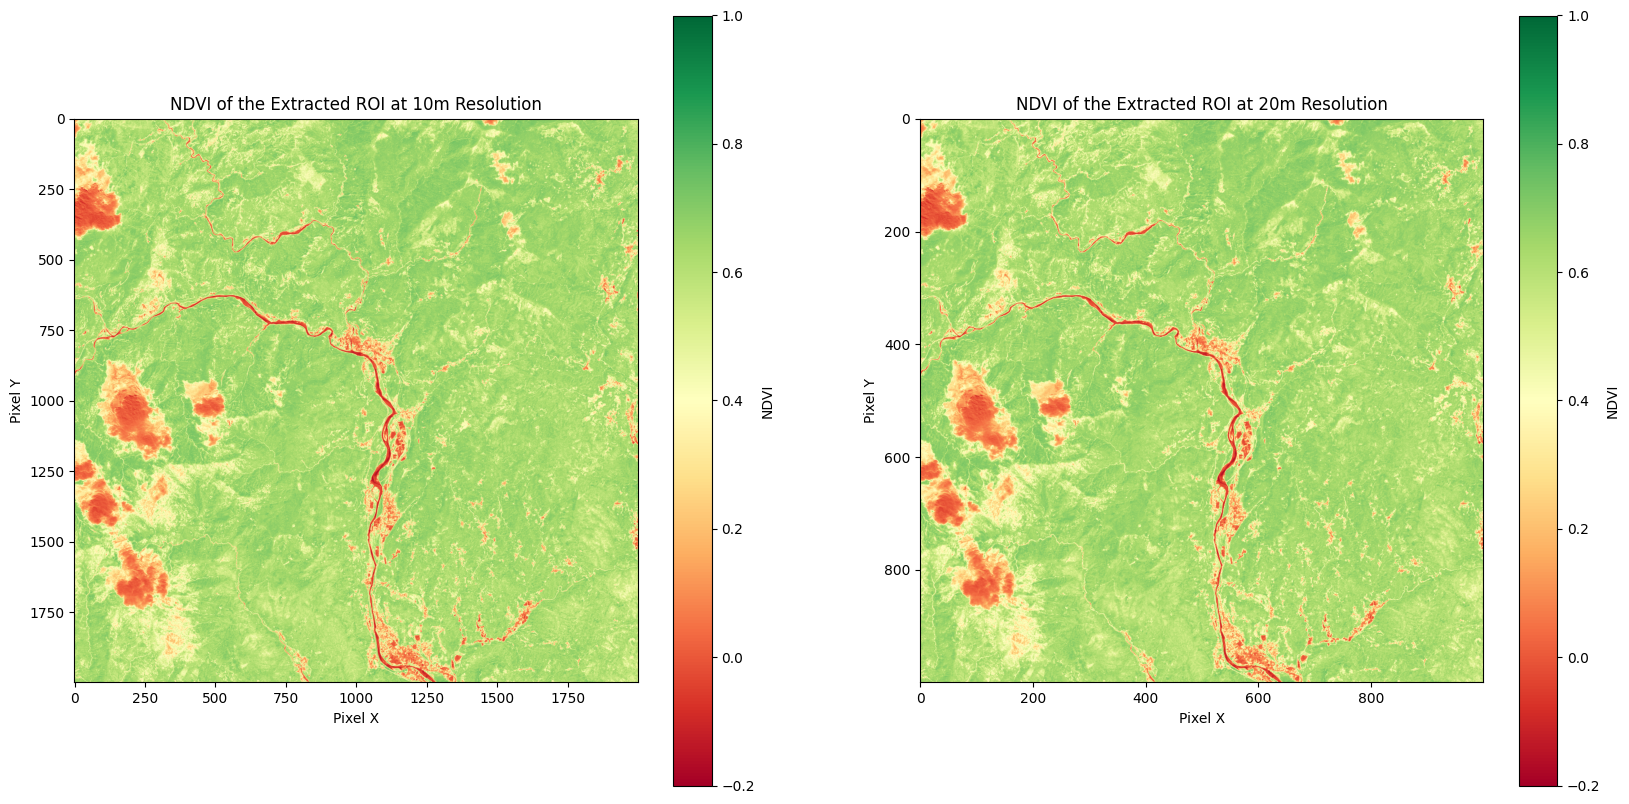

In [25]:
roi_10m_bands = []
for band_path in bands_10m:
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_10m).astype(np.float32)
        roi_10m_bands.append(band_roi)

roi_20m_bands = []
for band_path in bands_20m:
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_20m).astype(np.float32)
        roi_20m_bands.append(band_roi)

dict_roi20m = {}
for band_path in bands_20m:
    band_name = band_path.stem.split('_')[-2] 
    with rasterio.open(band_path) as src:
        band_roi = src.read(1, window=window_20m).astype(np.float32)
        dict_roi20m[band_name] = band_roi
print("\nExtracted bands at 20m resolution stored in dictionary with keys:")
for key in dict_roi20m.keys():
    print(key)

#useful for computing downsampled NDVI at 20m resolution by averaging the values of the 4 pixels that correspond to each pixel at 20m resolution
ndvi_roi_20m = 0.25 * (
    ndvi_roi_10m[0::2, 0::2] +
    ndvi_roi_10m[1::2, 0::2] +
    ndvi_roi_10m[0::2, 1::2] +
    ndvi_roi_10m[1::2, 1::2]
)

#sanity check on the shapes of the extracted bands
print("\nShapes of extracted 10m bands:")
for i, band in enumerate(roi_10m_bands):
    print(f"Band {i+1}: {band.shape}")
print("\nShapes of extracted 20m bands:")
for i, band in enumerate(roi_20m_bands):
    print(f"Band {i+1}: {band.shape}")

plt.subplots(1, 2, figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.imshow(ndvi_roi_10m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')  
plt.title('NDVI of the Extracted ROI at 10m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.subplot(1, 2, 2)
plt.imshow(ndvi_roi_20m, cmap='RdYlGn', vmin=-0.2, vmax=1.0)
plt.colorbar(label='NDVI')
plt.title('NDVI of the Extracted ROI at 20m Resolution')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

In [10]:
import json
from rasterio.windows import bounds as window_bounds

b05_20m = bands_20m[4] # Assuming B05 is the second band in the 20m list

with rasterio.open(b05_20m) as src20:
    roi_bounds_utm = window_bounds(window_20m, transform=src20.transform)
    roi_crs = src20.crs.to_string()
    roi_transform = src20.window_transform(window_20m)

print("CRS:", roi_crs) 
print("ROI bounds (xmin, ymin, xmax, ymax):", roi_bounds_utm)

roi_20m_data = {
    "crs": roi_crs,
    "bounds" : {
        "xmin": roi_bounds_utm[0],
        "ymin": roi_bounds_utm[1],
        "xmax": roi_bounds_utm[2],
        "ymax": roi_bounds_utm[3]
    },
    "grid20" : {
        "transform": roi_transform.to_gdal(), 
        "width": window_20m.width,
        "height": window_20m.height
    }
}

Path("roi_20m_metadata.json").write_text(json.dumps(roi_20m_data, indent=4))

CRS: EPSG:32632
ROI bounds (xmin, ymin, xmax, ymax): (431960.0, 5061800.0, 451960.0, 5081800.0)


373

# SNAP LAI

In [ ]:
print(window_20m)
print("Snap coordinates for the 20m grid:")
'''
Scene start X = 1600
Scene start Y = 910
Scene end X = 2599
Scene end Y = 1909
'''

Window(col_off=1600, row_off=910, width=1000, height=1000)


'Scene start X = 1600\nScene start Y = 910\nScene end X = 2599\nScene end Y = 1909'

Shape: (1000, 1000)
CRS: EPSG:32632
Transform: | 20.00, 0.00, 431960.00|
| 0.00,-20.00, 5081800.00|
| 0.00, 0.00, 1.00|
Dtype: float32
Min: -0.44200388
Max: 7.945994
Mean: 2.720043


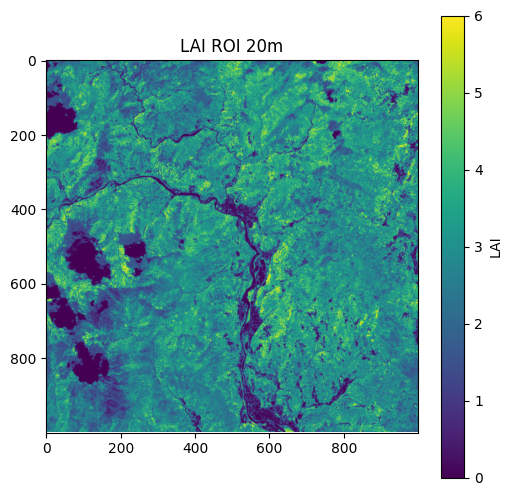

Valid pixels: 1000000
Total pixels: 1000000


In [15]:
lai_path = "LAI_ROI_20m.tif"

with rasterio.open(lai_path) as src:
    lai = src.read(1)
    print("Shape:", lai.shape)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Dtype:", lai.dtype)
    print("Min:", np.nanmin(lai))
    print("Max:", np.nanmax(lai))
    print("Mean:", np.nanmean(lai))

import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.imshow(lai, cmap="viridis", vmin=0, vmax=6)
plt.colorbar(label="LAI")
plt.title("LAI ROI 20m")
plt.show()

print("Valid pixels:", np.sum(np.isfinite(lai)))
print("Total pixels:", lai.size)



In [ ]:
import numpy as np

neg = np.sum(lai < 0)
p99 = np.nanpercentile(lai, 99)
p999 = np.nanpercentile(lai, 99.9)

print("Negatives:", neg, " (", 100*neg/lai.size, "% )")
print("P99:", p99, " P99.9:", p999)

lai_clean = lai.copy()
lai_clean[lai_clean < 0] = np.nan
lai_clean = np.clip(lai_clean, 0, 6)  # soglia conservativa

print("lai_clean stats:")
print("Min:", np.nanmin(lai_clean))
print("Max:", np.nanmax(lai_clean))
print("Mean:", np.nanmean(lai_clean))

#Scaling LAI values to be between 0 and 1 by dividing by 10,000
for k in dict_roi20m:
    dict_roi20m[k] = dict_roi20m[k] / 10000.0

# ricontrollo range
for k in ["B05","B06","B07","B8A","B11","B12"]:
    a = dict_roi20m[k]
    print(k, "min:", float(np.nanmin(a)), "max:", float(np.nanmax(a)))

Negatives: 26239  ( 2.6239 % )
P99: 4.989893  P99.9: 5.8035283
lai_clean stats:
Min: 0.0
Max: 6.0
Mean: 2.8035944
B05 min: 0.09549999982118607 max: 1.7204999923706055
B06 min: 0.0706000030040741 max: 1.6818000078201294
B07 min: 0.07329999655485153 max: 1.6663999557495117
B8A min: 0.08100000023841858 max: 1.653499960899353
B11 min: 0.11230000108480453 max: 1.5911999940872192
B12 min: 0.10660000145435333 max: 1.6131000518798828


# Dataset

In [ ]:
feature_order = ["B05","B06","B07","B8A","B11","B12"]
X_stack = np.stack([dict_roi20m[b] for b in feature_order] + [ndvi_roi_20m], axis=-1)
print("Stacked feature array shape:", X_stack.shape)

mask = np.isfinite(X_stack).all(axis=-1) & np.isfinite(lai_clean)




Stacked feature array shape: (1000, 1000, 7)
